# Log-normal random fields: information beyond the power spectrum

Code for Sect. 3.3 and 3.4 of *Optimal cosmological cross-correlation analysis with U-Net-based processing* (W. Yan, D. Gruen, O. Friedrich, A. Kovács). It reproduces Figs. 4–7 and Tables 3 and 4.

The Gaussian fields $A_1$, $A_2$ are generated exactly as in `unet_gaussian.ipynb` (broken power law of Eq. 10, high-frequency cutoff at mode $k = 20$ for $A_2$, independent seeds) and one of them is made log-normal by $\exp(50\,A)$. For non-Gaussian fields the linear filter $W = P_{IT}/P_{II}$ is no longer optimal, so an output $\mathbf{O}$ that correlates better with $\mathbf{T}$ than the linear estimator $\mathbf{L}$ shows that the network uses information beyond the power spectrum.

All shared code is in `unet_tools.py`. Training needs a GPU; the training set of Sect. 3.3 (200 000 pairs) takes about 7 GB of memory.

In [1]:
import os
import sys
from pathlib import Path

# Make unet_tools.py (stored next to this notebook) importable and write figures/weights
# next to the notebook, even if the kernel was started in another directory.
_nb_file = globals().get("__vsc_ipynb_file__")          # set by VS Code
NB_DIR = Path(_nb_file).parent if _nb_file else Path.cwd()
if not (NB_DIR / "unet_tools.py").exists():
    raise FileNotFoundError(f"unet_tools.py not found in {NB_DIR}; start the notebook from its own folder")
sys.path.insert(0, str(NB_DIR))
os.chdir(NB_DIR)

import numpy as np
import matplotlib.pyplot as plt
import torch

import unet_tools as ut
from unet_tools import gaussian_random_field, K_CUTOFF

ut.set_paper_style()
FIG_DIR = "figures"
print("device:", ut.get_device())

device: cuda


## Sect. 3.3 — Log-normal fields as input and target

$\mathbf{I} = 100\,A_1 + \exp(50\,A_2)$ and $\mathbf{T} = \exp(50\,A_2)$, with $A_1$, $A_2$ Gaussian (amplitude 10) from independent seeds, $A_2$ band limited; $\exp(50 A_2)$ is mean-subtracted. The linear estimator $\mathbf{L}$ is the input filtered with the measured $W(k) = P_{IT}/P_{II}$ (Eq. 7).

In [2]:
SEED_OFFSET = 1_000_000

def make_pair_lognormal_target(seed):
    """I = 100 A1 + exp(50 A2), T = exp(50 A2)  (A2 band limited, exp(50 A2) mean-subtracted)."""
    A1 = gaussian_random_field(seed, amplitude=10.0)
    A2 = gaussian_random_field(seed + SEED_OFFSET, amplitude=10.0, k_cutoff=K_CUTOFF)
    LN2 = np.exp(50.0 * A2)
    LN2 -= np.mean(LN2)
    return 100.0 * A1 + LN2, LN2

In [3]:
# ---- parameters (Sect. 3.3) ----
N_TRAIN, N_VAL, N_TEST = 200_000, 500, 1000   # pairs for training / validation / test
EPOCHS, LR, BATCH_SIZE = 2, 1e-5, 32
N_REAL, IDX_START = 100, 100                   # realizations averaged for the power spectra
N_HIST = 400                                   # realizations stacked in the 2D histogram
N_TABLE = 200                                  # realizations averaged for the table

In [4]:
training   = ut.generate_dataset(N_TRAIN, make_pair_lognormal_target, seed=0)
validation = ut.generate_dataset(N_VAL,   make_pair_lognormal_target, seed=500_000)
test_data  = ut.generate_dataset(N_TEST,  make_pair_lognormal_target, seed=600_000)

### Training

Periodic U-Net variant (`UNetCircular`) with ReLU after every layer, output included.

In [5]:
model = ut.UNetCircular(negative_slope=0.0, linear_output=False)
model = ut.train_model(model, training, validation, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE)
torch.save(model.state_dict(), "unet_lognormal_target.pt")

Epoch 1/2
  loss:  0.029673  [     0/200000]
  loss: -0.474093  [ 16000/200000]
  loss: -0.509866  [ 32000/200000]
  loss: -0.459417  [ 48000/200000]
  loss: -0.517367  [ 64000/200000]
  loss: -0.447908  [ 80000/200000]
  loss: -0.473783  [ 96000/200000]
  loss: -0.487557  [112000/200000]
  loss: -0.471465  [128000/200000]
  loss: -0.444186  [144000/200000]
  loss: -0.436683  [160000/200000]
  loss: -0.449062  [176000/200000]
  loss: -0.491324  [192000/200000]
  validation loss: -0.479299
Epoch 2/2
  loss: -0.470750  [     0/200000]
  loss: -0.463723  [ 16000/200000]
  loss: -0.465425  [ 32000/200000]
  loss: -0.492994  [ 48000/200000]
  loss: -0.472691  [ 64000/200000]
  loss: -0.431658  [ 80000/200000]
  loss: -0.455935  [ 96000/200000]
  loss: -0.511805  [112000/200000]
  loss: -0.493318  [128000/200000]
  loss: -0.452884  [144000/200000]
  loss: -0.467466  [160000/200000]
  loss: -0.467329  [176000/200000]
  loss: -0.465132  [192000/200000]
  validation loss: -0.478566


### Linear estimator

Auto and cross spectra averaged over the test set and the resulting filter $W(k) = P_{IT}/P_{II}$. Because of the mode coupling introduced by the log-normal transformation, $W$ is not exactly a step function, but it is still very close to the low-pass filter of the Gaussian cases.

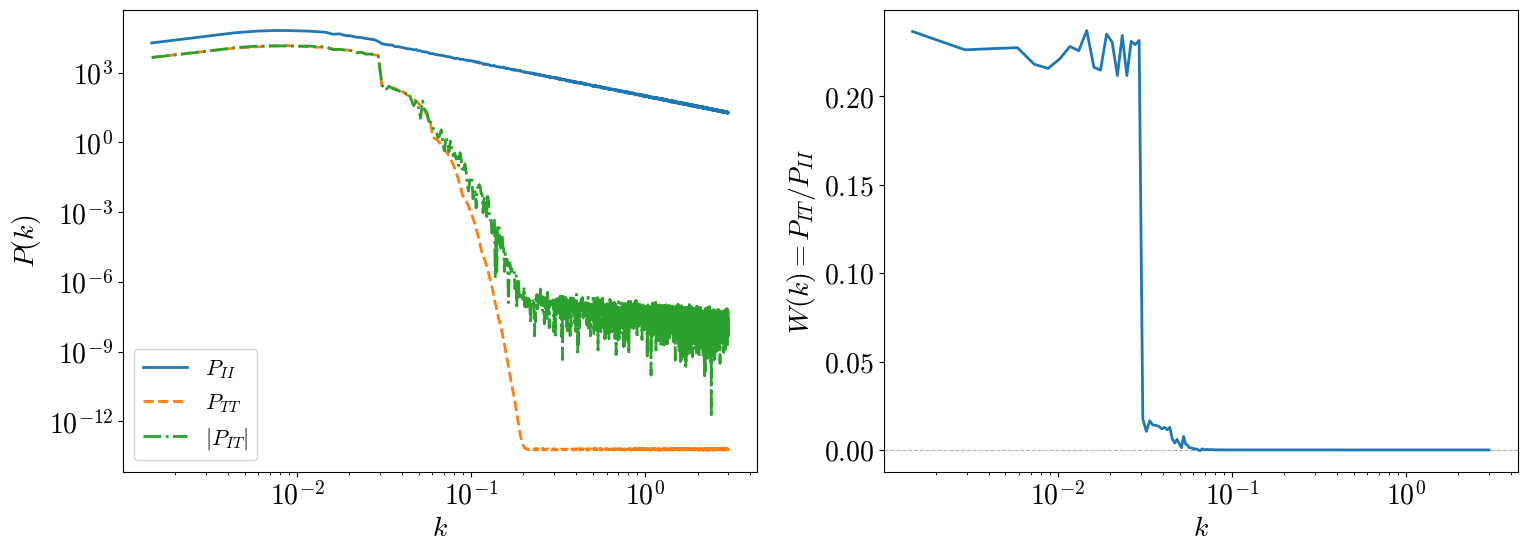

In [6]:
P_II, P_TT, P_IT, W = ut.measure_spectra(test_data)

def linear_estimator(I):
    """L: Fourier transform I, multiply by P_IT / P_II, transform back (Eq. 3 with Eq. 7)."""
    return ut.apply_filter(I, W)

fig = ut.plot_spectra_and_filter(P_II, P_TT, P_IT, W)
plt.show()

### Fig. 4a — one realization in real space

All curves normalized to unit variance; $\mathbf{I}$ and $\mathbf{T}$ are shifted upwards by 2.

Saved figure to: figures/fig4a_lognormal_target_fields.pdf


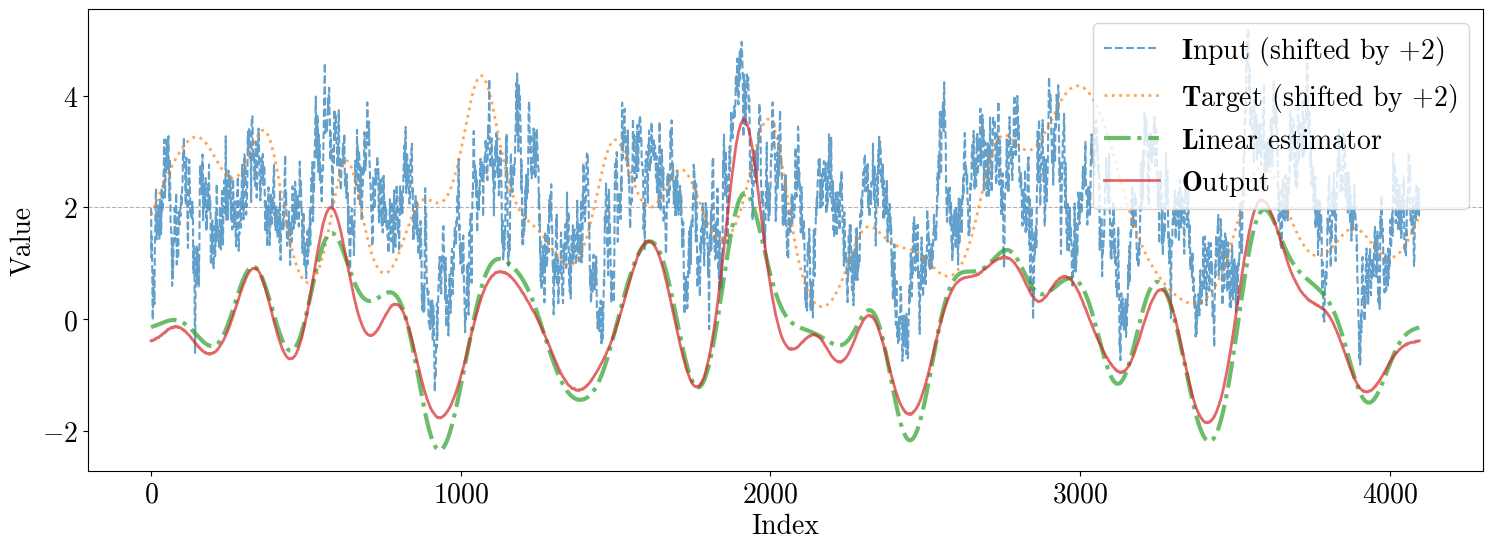

In [7]:
OFFSET = 2.0

I, T = ut.get_fields(test_data, 0)
L = linear_estimator(I)
O = ut.predict(model, I)
I_n, T_n, L_n, O_n = (ut.normalize(f) for f in (I, T, L, O))

fig = ut.plot_fields(
    [(I_n + OFFSET, ut.shifted(ut.LABEL_I, OFFSET), ut.STYLE_I),
     (T_n + OFFSET, ut.shifted(ut.LABEL_T, OFFSET), ut.STYLE_T),
     (L_n, ut.LABEL_L, ut.STYLE_L),
     (O_n, ut.LABEL_O, ut.STYLE_O)],
    baseline=OFFSET, legend_size=20,
    figsize=(18, 9)
)
ut.save_figure(fig, "fig4a_lognormal_target_fields.pdf", FIG_DIR)
plt.show()

### Fig. 4b — power spectra, mean of 100 realizations

Each field is normalized to unit variance and rescaled to the standard deviation of the input of the same realization; the input is then matched to the target at low $k$.

Saved figure to: figures/fig4b_lognormal_target_power_spectra.pdf


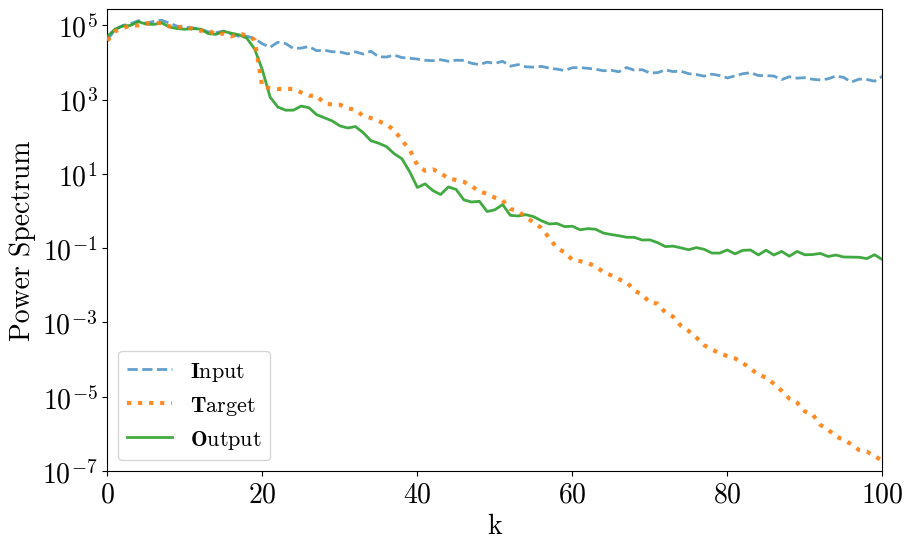

In [8]:
I_stack, T_stack = ut.get_fields(test_data, range(IDX_START, IDX_START + N_REAL))
O_stack = ut.predict(model, I_stack)
I_std = I_stack.std(axis=1)

fig = ut.plot_power_spectra(ut.mean_powerspectrum(I_stack, I_std),
                            ut.mean_powerspectrum(T_stack, I_std),
                            ut.mean_powerspectrum(O_stack, I_std), ymin=1e-7)
ut.save_figure(fig, "fig4b_lognormal_target_power_spectra.pdf", FIG_DIR)
plt.show()

### Fig. 5 — 2D histogram of normalized $\mathbf{I}$ and $\mathbf{O}$

Pixels of 400 realizations (each field normalized to zero mean and unit variance). The mean of $\mathbf{O}$ in bins of $\mathbf{I}$ is fitted with a parabola, Eq. (14).

O = 0.10 I^2 + 0.73 I -0.10
Saved figure to: figures/fig5_lognormal_target_hist2d_parabola.pdf


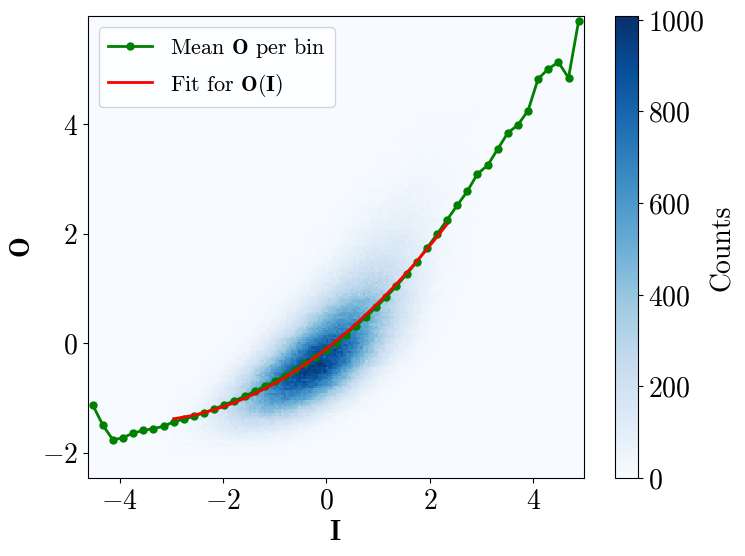

In [9]:
I_all, _ = ut.get_fields(test_data, range(N_HIST))
O_all = ut.predict(model, I_all)
I_flat = np.concatenate([ut.normalize(f) for f in I_all])
O_flat = np.concatenate([ut.normalize(f) for f in O_all])

centers, means = ut.binned_mean(I_flat, O_flat, n_bins=50)
popt, x_fit = ut.fit_parabola(centers, means, x_range=(-3.0, 2.5))
print("O = {:.2f} I^2 + {:.2f} I {:+.2f}".format(*popt))

x_plot = np.linspace(x_fit.min(), x_fit.max(), 100)
fig = ut.plot_hist2d(I_flat, O_flat, centers, means,
                     fit=(x_plot, ut.parabola(x_plot, *popt), r"Fit for $\mathbf{O}(\mathbf{I})$"))
ut.save_figure(fig, "fig5_lognormal_target_hist2d_parabola.pdf", FIG_DIR)
plt.show()

### Fig. 6 — parabolic transformation + low-pass filter vs. the network output

$\mathbf{PF}$ applies the fitted parabola to the normalized input and then the low-pass filter. All curves are normalized and shown on the scale of $\mathbf{T}$; the lower panel shows $\mathbf{O} - \mathbf{PF}$ and $\mathbf{O} - \mathbf{L}$.

Saved figure to: figures/fig6_lognormal_target_parabolic_filter.pdf


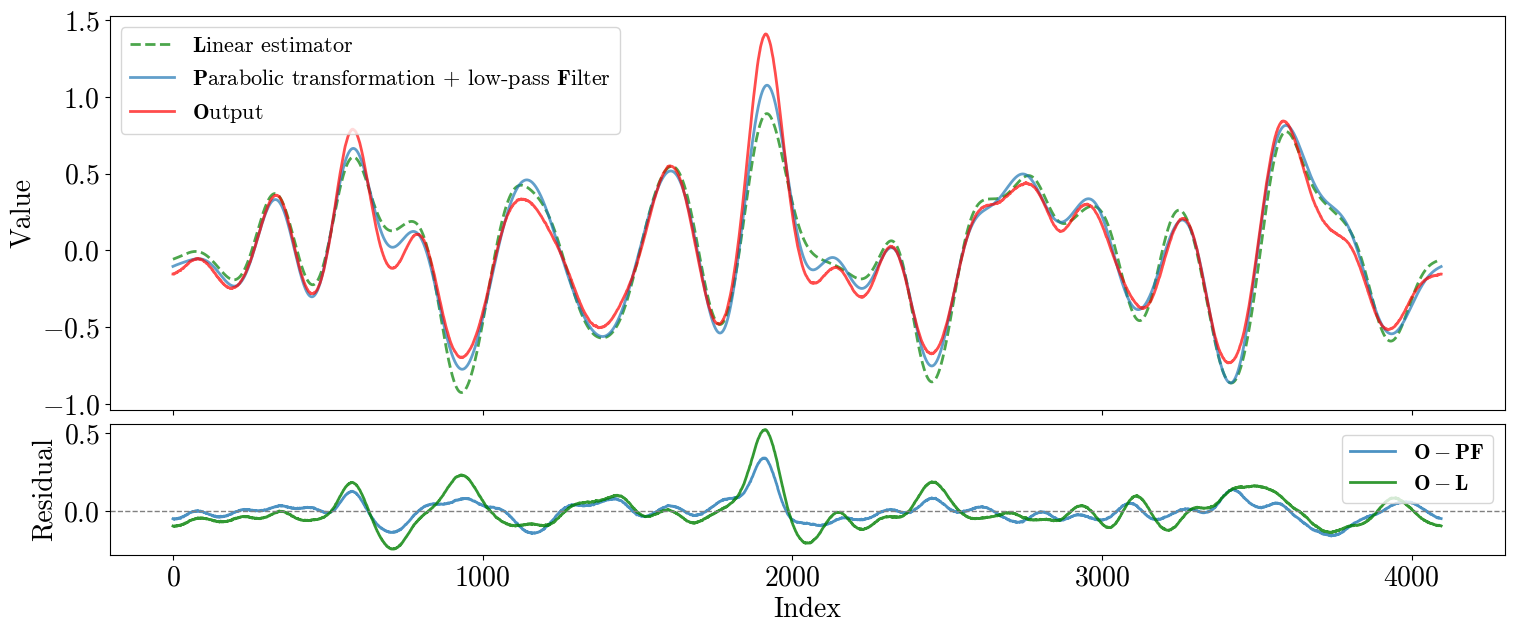

In [10]:
def parabolic_then_lowpass(I):
    """PF: parabolic transformation of Eq. (14) applied to the normalized input, then low-pass filtered."""
    return ut.low_pass_filter(ut.parabola(ut.normalize(I), *popt))

I, T = ut.get_fields(test_data, 0)
L, PF, O = linear_estimator(I), parabolic_then_lowpass(I), ut.predict(model, I)
s = np.std(T)
L_n, PF_n, O_n = (ut.normalize(f) * s for f in (L, PF, O))

fig = ut.plot_fields(
    [(L_n, ut.LABEL_L, dict(color="green", alpha=0.7, linestyle="--", linewidth=2.0)),
     (PF_n, r"$\mathbf{P}$arabolic transformation + low-pass $\mathbf{F}$ilter",
      dict(color="tab:blue", alpha=0.7, linestyle="-", linewidth=2.0)),
     (O_n, ut.LABEL_O, dict(color="red", alpha=0.7, linewidth=2.0))],
    residuals=[(O_n - PF_n, r"$\mathbf{O} - \mathbf{PF}$", dict(color="tab:blue", alpha=0.8, linewidth=2.0)),
               (O_n - L_n, r"$\mathbf{O} - \mathbf{L}$", dict(color="green", alpha=0.8, linewidth=2.0))],
)
ut.save_figure(fig, "fig6_lognormal_target_parabolic_filter.pdf", FIG_DIR)
plt.show()

### Table 3

In [11]:
table3 = ut.correlation_table(test_data, {
    "I":  lambda I: I,
    "L":  linear_estimator,
    "O":  lambda I: ut.predict(model, I),
    "PF": parabolic_then_lowpass,
}, n=N_TABLE)

Pearson correlation with T, mean +- std over 200 realizations
     I vs T : 0.351 +- 0.100
     L vs T : 0.467 +- 0.122
     O vs T : 0.478 +- 0.133
    PF vs T : 0.474 +- 0.126


## Sect. 3.4 — Log-normal input and Gaussian target

$\mathbf{I} = \exp(50\,A_1) + 100\,A_2$ and $\mathbf{T} = A_2$: a log-normal tracer cross-correlated with a Gaussian field, analogous to a galaxy overdensity field and the ISW signal. Here the U-Net of Fig. 1 (`UNet`: valid convolutions, transposed-convolution up-sampling, ReLU output) is used, and $\mathbf{L}$ is the low-pass filtered input.

In [12]:
def make_pair_lognormal_input(seed):
    """I = exp(50 A1) + 100 A2, T = A2  (exp(50 A1) mean-subtracted, A2 band limited)."""
    A1 = gaussian_random_field(seed, amplitude=10.0)
    A2 = gaussian_random_field(seed + SEED_OFFSET, amplitude=10.0, k_cutoff=K_CUTOFF)
    LN1 = np.exp(50.0 * A1)
    LN1 -= np.mean(LN1)
    return LN1 + 100.0 * A2, A2

In [13]:
# ---- parameters (Sect. 3.4) ----
N_TRAIN, N_VAL, N_TEST = 50_000, 500, 400
EPOCHS, LR, BATCH_SIZE = 3, 1e-4, 32
N_REAL, IDX_START = 100, 100
N_HIST = 400
N_TABLE = 200

In [14]:
training   = ut.generate_dataset(N_TRAIN, make_pair_lognormal_input, seed=0)
validation = ut.generate_dataset(N_VAL,   make_pair_lognormal_input, seed=500_000)
test_data  = ut.generate_dataset(N_TEST,  make_pair_lognormal_input, seed=600_000)

In [15]:
model = ut.UNet()
model = ut.train_model(model, training, validation, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE)
torch.save(model.state_dict(), "unet_lognormal_input.pt")

Epoch 1/3
  loss: -0.295119  [     0/ 50000]
  loss: -0.946079  [ 16000/ 50000]
  loss: -0.964990  [ 32000/ 50000]
  loss: -0.970181  [ 48000/ 50000]
  validation loss: -0.971158
Epoch 2/3
  loss: -0.968634  [     0/ 50000]
  loss: -0.969892  [ 16000/ 50000]
  loss: -0.977672  [ 32000/ 50000]
  loss: -0.978580  [ 48000/ 50000]
  validation loss: -0.978322
Epoch 3/3
  loss: -0.977382  [     0/ 50000]
  loss: -0.976287  [ 16000/ 50000]
  loss: -0.981522  [ 32000/ 50000]
  loss: -0.980183  [ 48000/ 50000]
  validation loss: -0.981749


### Fig. 7a — one realization in real space

Saved figure to: figures/fig7a_lognormal_input_fields.pdf


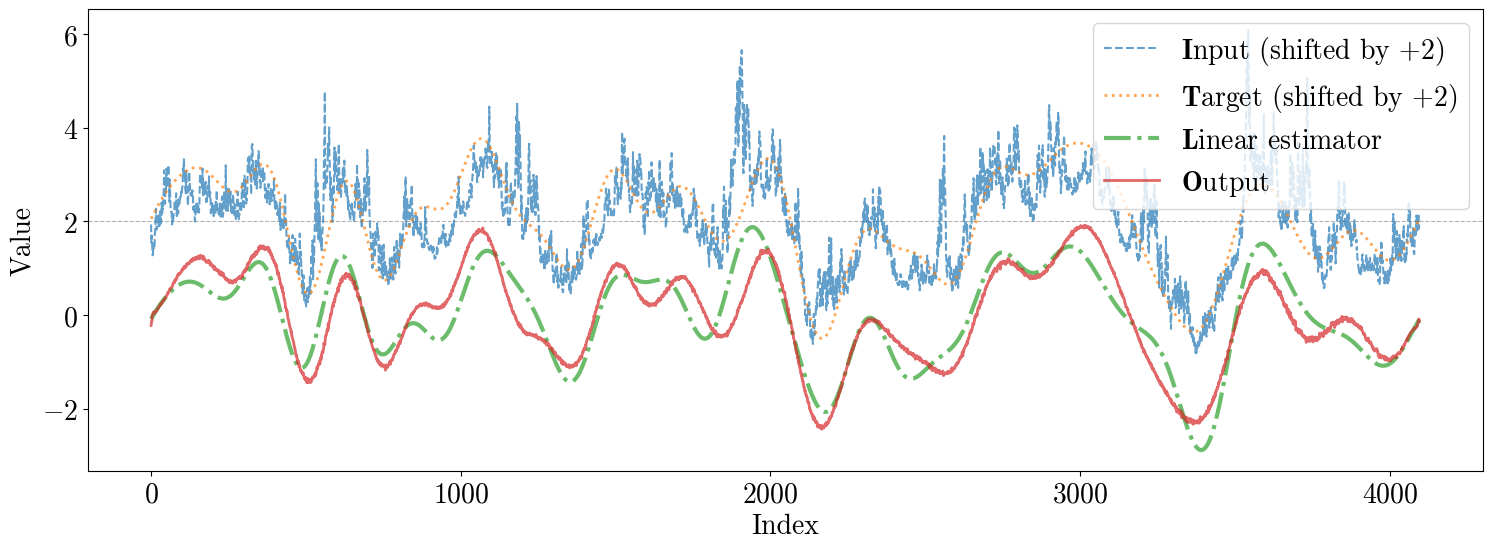

In [16]:
OFFSET = 2.0

I, T = ut.get_fields(test_data, 0)
L = ut.low_pass_filter(I)
O = ut.predict(model, I)
I_n, T_n, L_n, O_n = (ut.normalize(f) for f in (I, T, L, O))

fig = ut.plot_fields(
    [(I_n + OFFSET, ut.shifted(ut.LABEL_I, OFFSET), ut.STYLE_I),
     (T_n + OFFSET, ut.shifted(ut.LABEL_T, OFFSET), ut.STYLE_T),
     (L_n, ut.LABEL_L, ut.STYLE_L),
     (O_n, ut.LABEL_O, ut.STYLE_O)],
    baseline=OFFSET, legend_size=20,
    figsize=(18, 9)
)
ut.save_figure(fig, "fig7a_lognormal_input_fields.pdf", FIG_DIR)
plt.show()

### Fig. 7b — power spectra, mean of 100 realizations

Saved figure to: figures/fig7b_lognormal_input_power_spectra.pdf


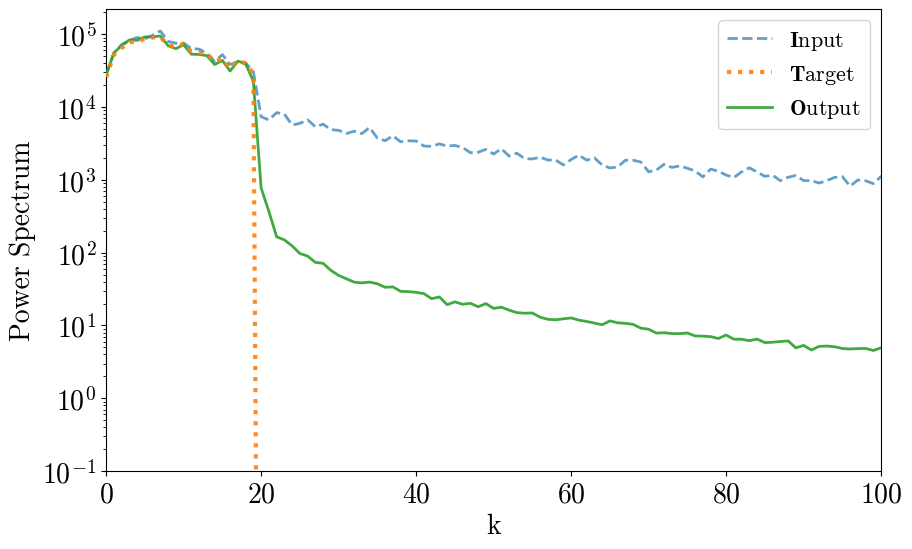

In [17]:
I_stack, T_stack = ut.get_fields(test_data, range(IDX_START, IDX_START + N_REAL))
O_stack = ut.predict(model, I_stack)
I_std = I_stack.std(axis=1)

fig = ut.plot_power_spectra(ut.mean_powerspectrum(I_stack, I_std),
                            ut.mean_powerspectrum(T_stack, I_std),
                            ut.mean_powerspectrum(O_stack, I_std), ymin=1e-1)
ut.save_figure(fig, "fig7b_lognormal_input_power_spectra.pdf", FIG_DIR)
plt.show()

### Table 4

In [18]:
table4 = ut.correlation_table(test_data, {
    "I": lambda I: I,
    "L": ut.low_pass_filter,
    "O": lambda I: ut.predict(model, I),
}, n=N_TABLE)

Pearson correlation with T, mean +- std over 200 realizations
     I vs T : 0.760 +- 0.056
     L vs T : 0.863 +- 0.046
     O vs T : 0.982 +- 0.007


### 2D histogram of $\mathbf{I}$ and $\mathbf{O}$ (not shown in the paper)

Same analysis as Fig. 5. In this case the mean of $\mathbf{O}$ per $\mathbf{I}$ bin shows no parabolic feature (the quadratic coefficient of the fit is close to zero), as stated in Sect. 3.4.2.

O = -0.09 I^2 + 0.78 I +0.08


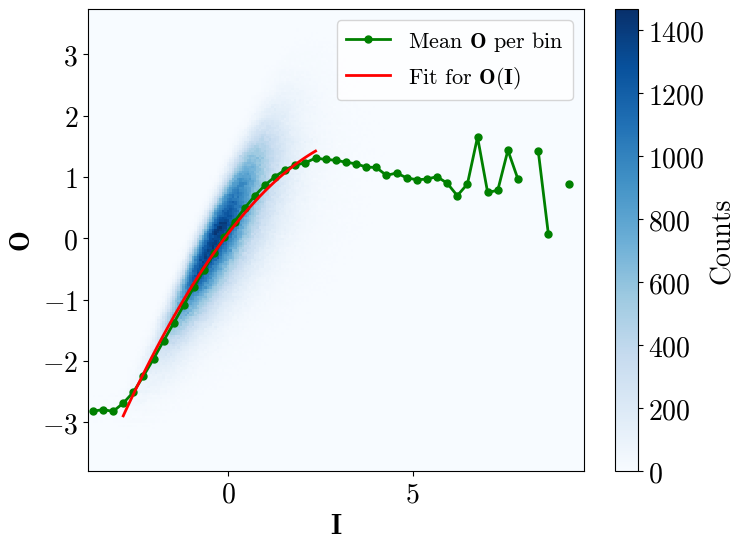

In [19]:
I_all, _ = ut.get_fields(test_data, range(N_HIST))
O_all = ut.predict(model, I_all)
I_flat = np.concatenate([ut.normalize(f) for f in I_all])
O_flat = np.concatenate([ut.normalize(f) for f in O_all])

centers, means = ut.binned_mean(I_flat, O_flat, n_bins=50)
popt, x_fit = ut.fit_parabola(centers, means, x_range=(-3.0, 2.5))
print("O = {:.2f} I^2 + {:.2f} I {:+.2f}".format(*popt))

x_plot = np.linspace(x_fit.min(), x_fit.max(), 100)
fig = ut.plot_hist2d(I_flat, O_flat, centers, means,
                     fit=(x_plot, ut.parabola(x_plot, *popt), r"Fit for $\mathbf{O}(\mathbf{I})$"))
plt.show()